In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("social_media_engagement_5000.csv")

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [2]:
# Check dataset structure
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

Dataset Shape: (5000, 19)

Column Names:
Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')


In [3]:
# Check data types
print("Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Data Types:
user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non

In [7]:
# Convert posted_at column to datetime format
df['posted_at'] = pd.to_datetime(df['posted_at'], dayfirst=True)

# Check the updated data type
print(df['posted_at'].dtype)

datetime64[ns]


In [8]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [9]:
# Fill missing numerical values using median
df['age'] = df['age'].fillna(df['age'].median())
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())

# Fill missing categorical values using mode
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] = df['sentiment'].fillna(df['sentiment'].mode()[0])

# Check missing values again
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [10]:
# Check duplicate rows
print("Duplicate rows before removal:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check again
print("Duplicate rows after removal:", df.duplicated().sum())

Duplicate rows before removal: 0
Duplicate rows after removal: 0


In [11]:
# Check gender values before cleaning
print("Before Cleaning:")
print(df['gender'].value_counts())

# Standardize gender labels
df['gender'] = df['gender'].astype(str).str.strip().str.title()

# Check after cleaning
print("\nAfter Cleaning:")
print(df['gender'].value_counts())

Before Cleaning:
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

After Cleaning:
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


In [12]:
# Check sentiment values before cleaning
print("Before Cleaning:")
print(df['sentiment'].value_counts())

# Clean and standardize sentiment labels
df['sentiment'] = df['sentiment'].astype(str).str.strip().str.title()

# Check sentiment values after cleaning
print("\nAfter Cleaning:")
print(df['sentiment'].value_counts())

Before Cleaning:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

After Cleaning:
sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


In [13]:
# Check minimum and maximum values
print("Likes:")
print("Min:", df['likes'].min(), "Max:", df['likes'].max())

print("\nComments:")
print("Min:", df['comments'].min(), "Max:", df['comments'].max())

print("\nShares:")
print("Min:", df['shares'].min(), "Max:", df['shares'].max())

# Check for negative values
print("\nNegative Values:")
print("Likes:", (df['likes'] < 0).sum())
print("Comments:", (df['comments'] < 0).sum())
print("Shares:", (df['shares'] < 0).sum())

Likes:
Min: 10.0 Max: 19998.0

Comments:
Min: 0.0 Max: 2999.0

Shares:
Min: 0.0 Max: 1999.0

Negative Values:
Likes: 0
Comments: 0
Shares: 0


In [14]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate']


In [15]:
# Display each column name separately
for column in df.columns:
    print(column)

user_id
age
gender
country
post_id
post_type
post_category
likes
comments
shares
watch_time_sec
impression_count
posted_at
follower_count
is_verified
device_type
sentiment
hashtags
engagement_rate


In [16]:
# Create hashtag count column
df['hashtag_count'] = df['hashtags'].fillna('').astype(str).str.count('#')

# Display hashtags and hashtag count
df[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [17]:
# Final data cleaning check
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicate Rows:", df.duplicated().sum())
print("Dataset Shape:", df.shape)

# Display cleaned dataset
df.head()

Total Missing Values: 0
Total Duplicate Rows: 0
Dataset Shape: (5000, 20)


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,Negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,Positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,Negative,#travel,2.777372,1


In [18]:
# View dataset structure

print("First 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

First 5 Rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,Negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,Positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,Negative,#travel,2.777372,1



Last 5 Rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,Positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3



Dataset Shape:
(5000, 20)

Column Names:
['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']


In [19]:
# Check data types
print("Data Types:")
print(df.dtypes)

# Display complete dataset information
print("\nDataset Information:")
df.info()

Data Types:
user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null 

In [20]:
# Generate summary statistics for numerical columns
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [21]:
# Analyze categorical distributions

# Value counts for post type
print("Post Type Distribution:")
print(df['post_type'].value_counts())

# Unique sentiment values
print("\nUnique Sentiment Values:")
print(df['sentiment'].unique())

# Number of unique countries
print("\nNumber of Unique Countries:")
print(df['country'].nunique())

# Gender distribution
print("\nGender Distribution:")
print(df['gender'].value_counts())

Post Type Distribution:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Unique Sentiment Values:
['Negative' 'Positive' 'Neutral']

Number of Unique Countries:
10

Gender Distribution:
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64


In [22]:
# Select numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Create correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation matrix
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [24]:
# Average likes by post type
avg_likes_post = df.groupby('post_type')['likes'].mean().sort_values(ascending=False)

print("Average Likes by Post Type:")
print(avg_likes_post)

# Average impressions by country
avg_impressions_country = df.groupby('country')['impression_count'].mean().sort_values(ascending=False)

print("\nAverage Impressions by Country:")
print(avg_impressions_country)

Average Likes by Post Type:
post_type
video    10188.600000
image    10104.865277
text     10100.148193
reel     10037.802416
Name: likes, dtype: float64

Average Impressions by Country:
country
India        52462.386916
France       51727.673387
USA          51263.872255
UK           51119.393509
Japan        49616.135593
Brazil       49193.174603
UAE          48928.413519
Canada       48703.150097
Germany      48605.406122
Australia    48346.383367
Name: impression_count, dtype: float64


In [25]:
# Create engagement score
df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

# Display the new column
df[['likes', 'comments', 'shares', 'engagement_score']].head(10)

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0
5,12535.0,1790.0,99.0,14424.0
6,11703.0,2276.0,1465.0,15444.0
7,9611.0,146.0,424.0,10181.0
8,10105.5,2379.0,1897.0,14381.5
9,14106.0,2480.0,1053.0,17639.0


In [26]:
# Create log-transformed impressions
df['log_impressions'] = np.log1p(df['impression_count'])

# Display original and transformed values
df[['impression_count', 'log_impressions']].head(10)

,impression_count,log_impressions
0,44650,10.706632
1,80216,11.292491
2,44858,10.711280
3,70455,11.162744
4,6019,8.702843
5,24893,10.122382
6,96327,11.475514
7,68446,11.133815
8,36283,10.499132
9,87972,11.384785


In [27]:
# GroupBy summary by Post Type
post_type_summary = df.groupby('post_type')[
    ['likes', 'comments', 'shares', 'engagement_score']
].mean()

print("Summary by Post Type:")
display(post_type_summary)

# GroupBy summary by Country
country_summary = df.groupby('country')[
    ['engagement_rate', 'impression_count', 'engagement_score']
].mean()

print("\nSummary by Country:")
display(country_summary)

# GroupBy summary by Sentiment
sentiment_summary = df.groupby('sentiment')[
    ['likes', 'comments', 'shares', 'engagement_rate', 'engagement_score']
].mean()

print("\nSummary by Sentiment:")
display(sentiment_summary)

Summary by Post Type:


,likes,comments,shares,engagement_score
post_type,,,,
image,10104.865277,1525.235766,1019.289495,12649.390537
reel,10037.802416,1504.187062,982.042089,12524.031567
text,10100.148193,1499.106024,1013.989558,12613.243775
video,10188.600000,1479.160000,996.834286,12664.594286



Summary by Country:


,engagement_rate,impression_count,engagement_score
country,,,
Australia,1.324339,48346.383367,12809.621704
Brazil,1.540704,49193.174603,12385.983135
Canada,0.916659,48703.150097,12605.894737
France,1.146402,51727.673387,12903.384073
Germany,0.759000,48605.406122,12635.664286
India,0.655005,52462.386916,12492.701869
Japan,0.769623,49616.135593,12578.648305
UAE,1.112352,48928.413519,12757.777336
UK,0.850966,51119.393509,12384.374239



Summary by Sentiment:


,likes,comments,shares,engagement_rate,engagement_score
sentiment,,,,,
Negative,10208.096875,1516.094792,1007.307292,1.038486,12731.498958
Neutral,9923.194499,1528.404060,996.565160,0.991170,12448.163720
Positive,10180.062077,1480.650617,1005.086749,0.919744,12665.799443


In [28]:
# Select required columns for statistical analysis
stats_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

# Mean
print("MEAN:")
print(df[stats_columns].mean())

# Median
print("\nMEDIAN:")
print(df[stats_columns].median())

# Mode
print("\nMODE:")
print(df[stats_columns].mode().iloc[0])

# Standard Deviation
print("\nSTANDARD DEVIATION:")
print(df[stats_columns].std())

# Variance
print("\nVARIANCE:")
print(df[stats_columns].var())

MEAN:
likes               10106.997400
comments             1502.039800
shares               1002.910600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

MEDIAN:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

MODE:
likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

STANDARD DEVIATION:
likes                5702.293017
comments              856.393312
shares                570.855200
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

VARIANCE:
likes              3.251615e+07
comments           7.334095e+05
shares             3.

In [29]:
# Calculate percentiles
percentiles = df[stats_columns].quantile([0.25, 0.50, 0.75])

print("PERCENTILES:")
display(percentiles)

PERCENTILES:


,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25


In [30]:
# Calculate skewness
print("SKEWNESS:")
print(df[stats_columns].skew())

# Calculate kurtosis
print("\nKURTOSIS:")
print(df[stats_columns].kurtosis())

SKEWNESS:
likes              -0.006894
comments            0.003802
shares             -0.014654
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64

KURTOSIS:
likes               -1.149992
comments            -1.144375
shares              -1.146857
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64


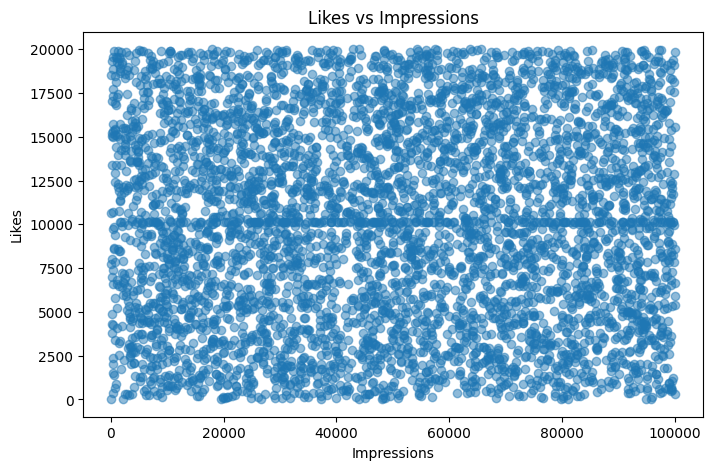

In [31]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter Plot: Likes vs Impressions
plt.figure(figsize=(8, 5))

plt.scatter(df['impression_count'], df['likes'], alpha=0.5)

plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')

plt.show()

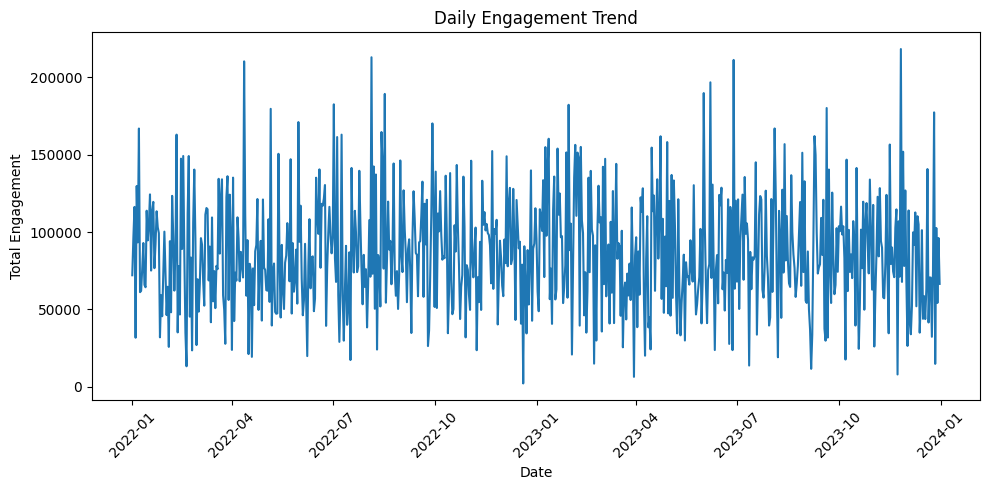

In [32]:
# Daily Engagement Trend
daily_engagement = (
    df.groupby(df['posted_at'].dt.date)['engagement_score']
    .sum()
)

plt.figure(figsize=(10, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Total Engagement')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

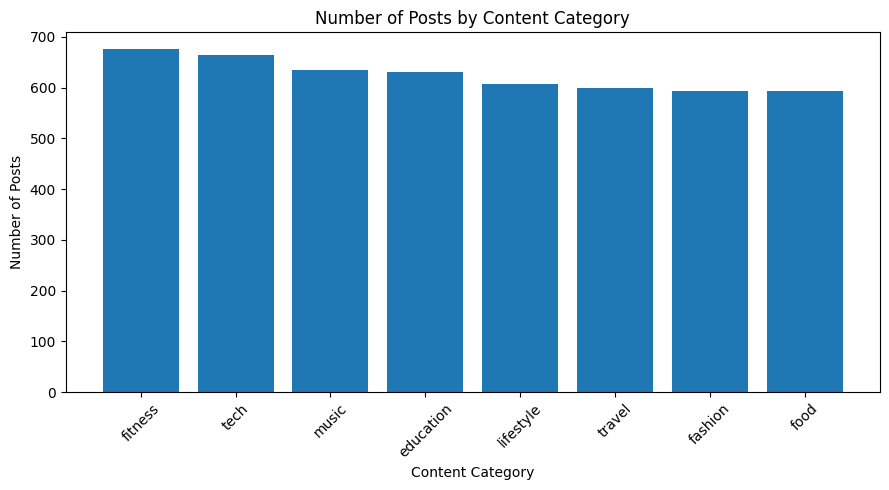

In [35]:
# Count posts by post category
category_counts = df['post_category'].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(category_counts.index, category_counts.values)

plt.title('Number of Posts by Content Category')
plt.xlabel('Content Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

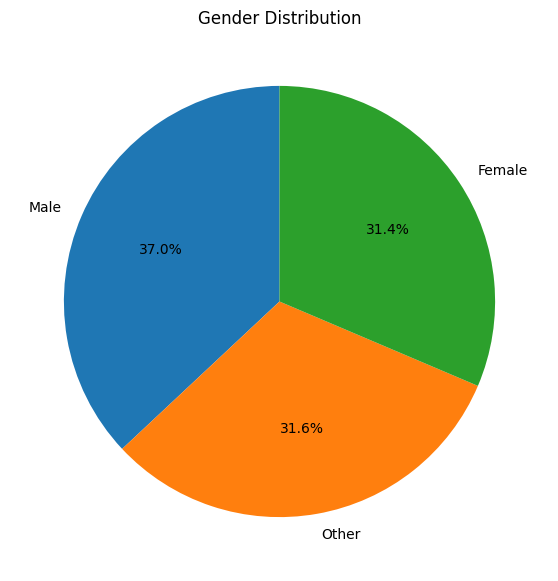

In [37]:
# Gender Distribution
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')
plt.show()

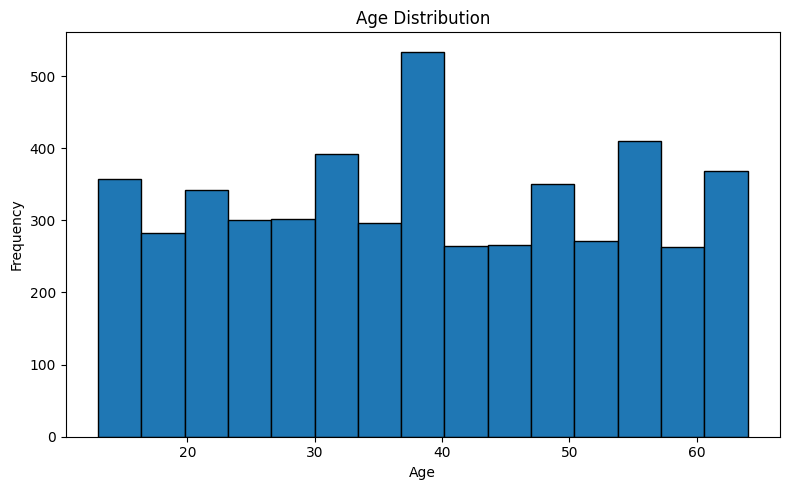

In [38]:
# Histogram: Age Distribution
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=15, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

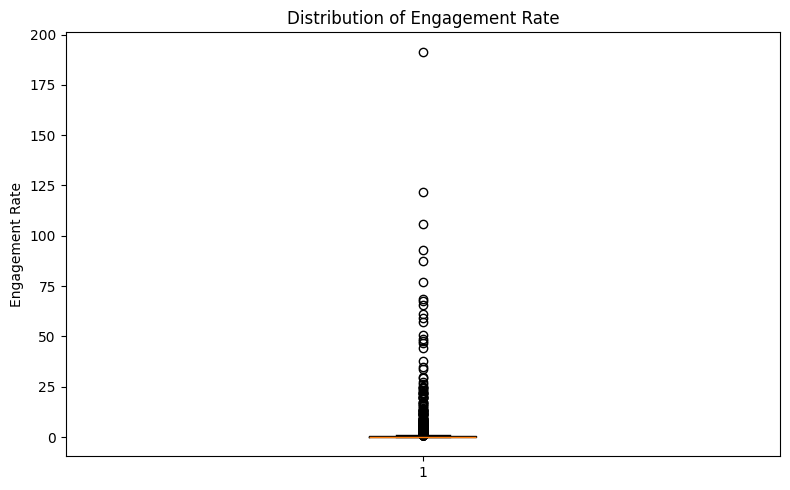

In [39]:
# Box Plot: Engagement Rate
plt.figure(figsize=(8, 5))

plt.boxplot(df['engagement_rate'].dropna())

plt.title('Distribution of Engagement Rate')
plt.ylabel('Engagement Rate')

plt.tight_layout()
plt.show()

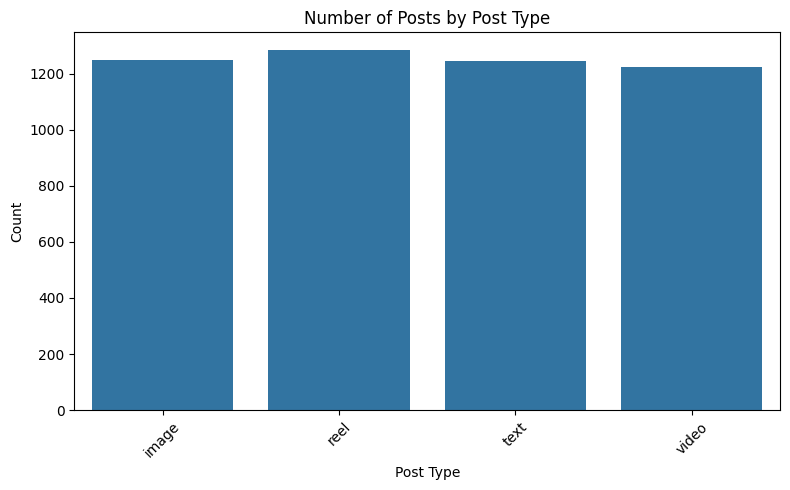

In [40]:
# Seaborn Count Plot: Post Type
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='post_type')

plt.title('Number of Posts by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

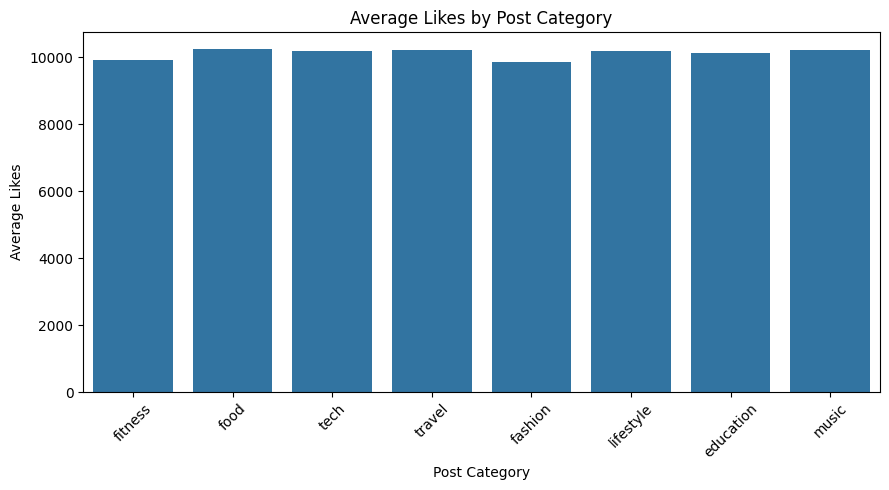

In [41]:
# Seaborn Bar Plot: Average Likes by Category
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    errorbar=None
)

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

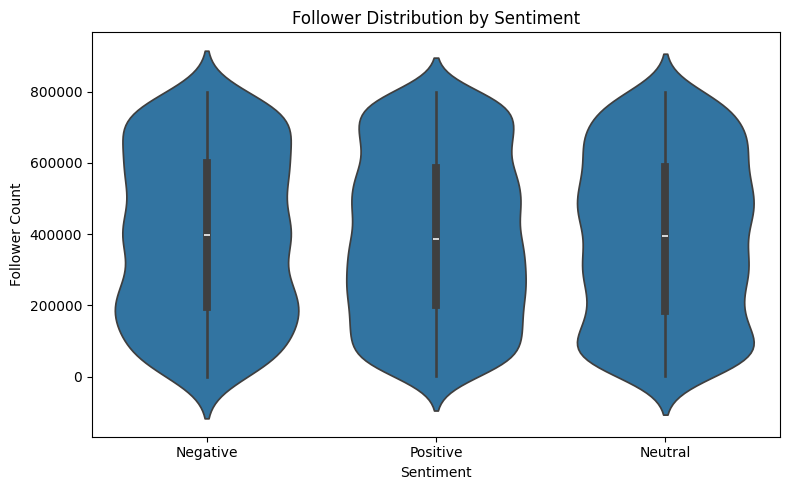

In [42]:
# Seaborn Violin Plot: Followers vs Sentiment
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Follower Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.tight_layout()
plt.show()

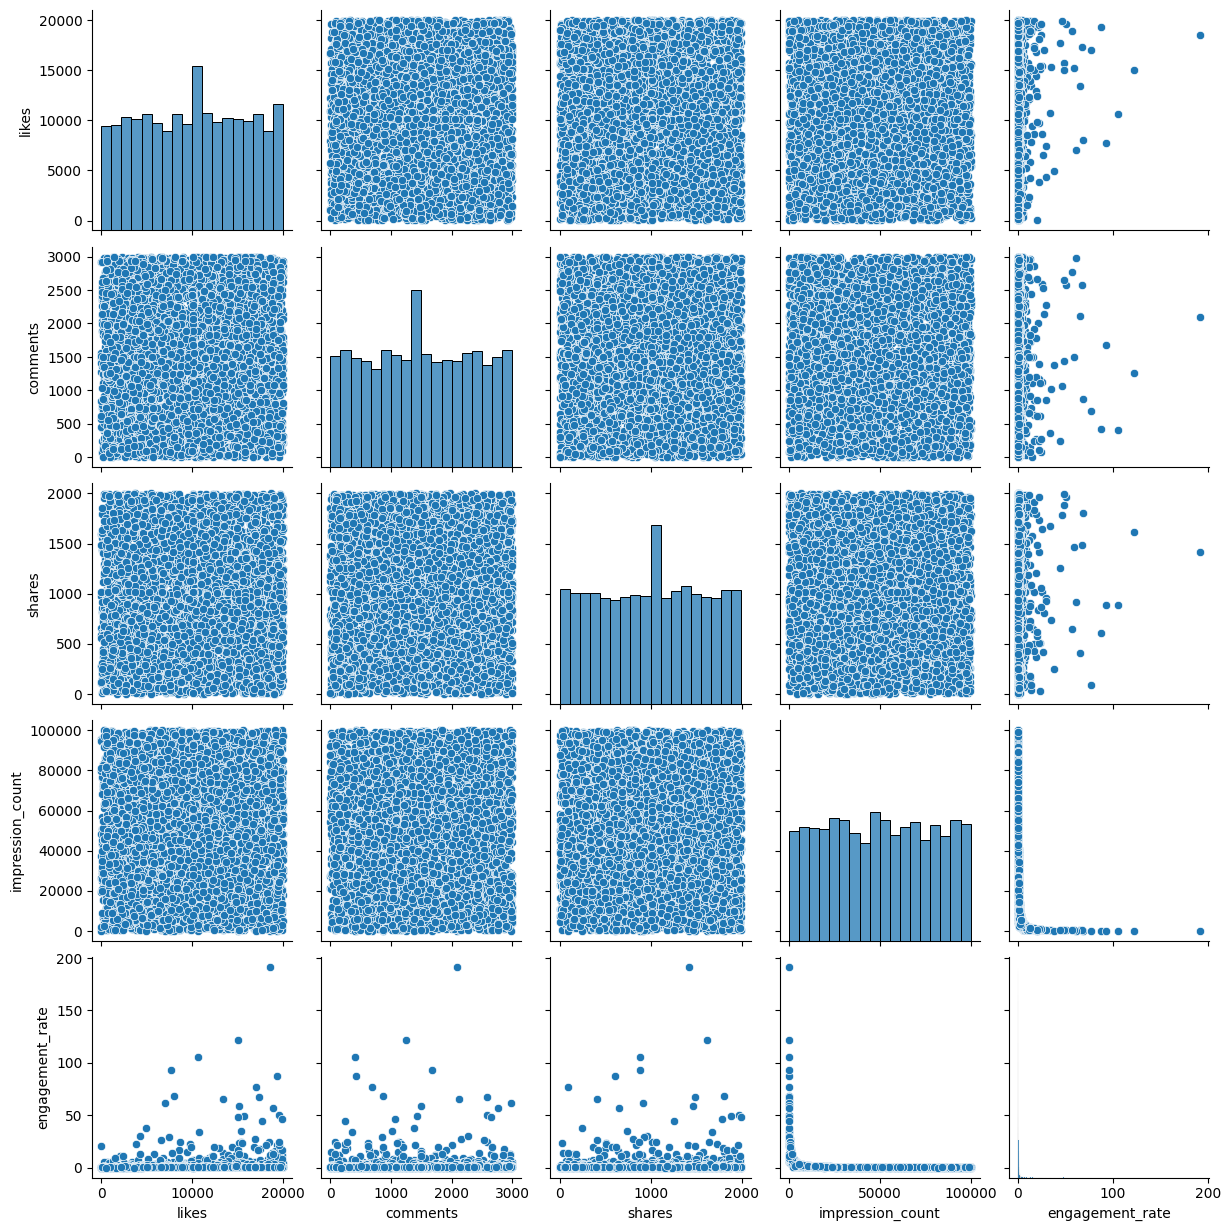

In [43]:
# Seaborn Pair Plot: Important Numeric Features
pairplot_columns = [
    'likes',
    'comments',
    'shares',
    'impression_count',
    'engagement_rate'
]

sns.pairplot(df[pairplot_columns])

plt.show()

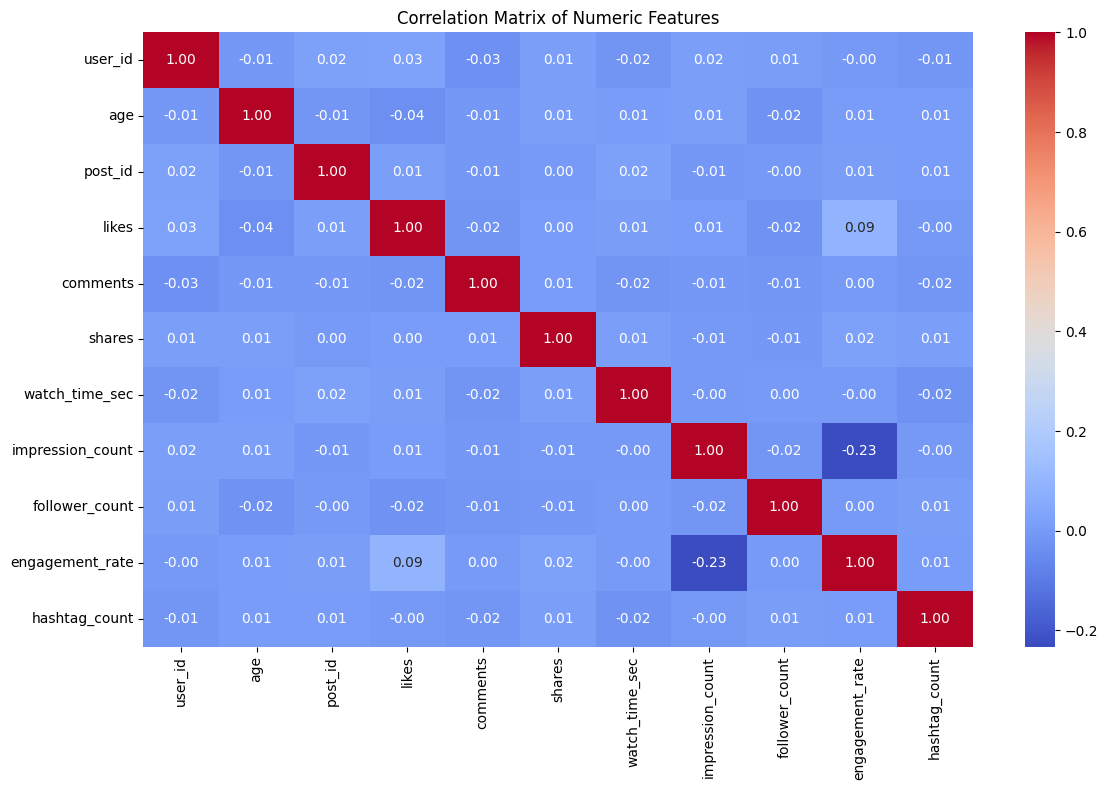

In [44]:
# Seaborn Heatmap: Correlation Matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix of Numeric Features')

plt.tight_layout()
plt.show()

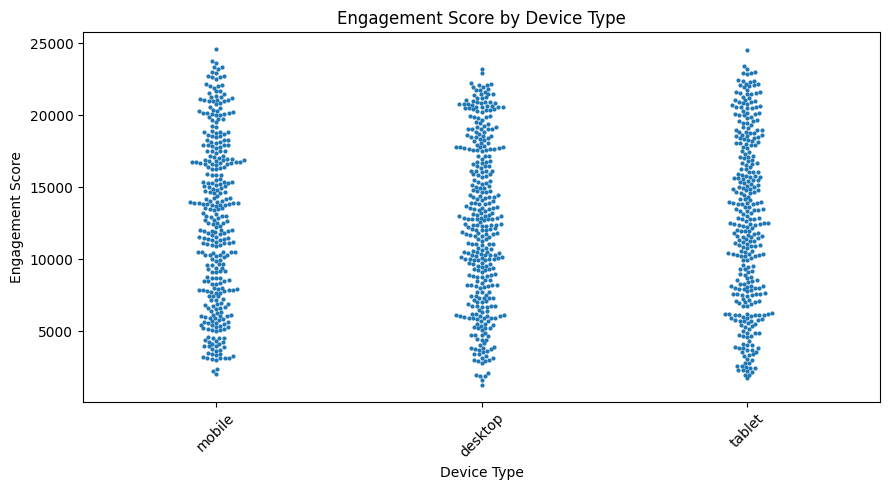

In [45]:
# Seaborn Swarm Plot: Engagement vs Device

# Take a sample to make the swarm plot faster and clearer
sample_df = df.sample(n=min(1000, len(df)), random_state=42)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_score',
    size=3
)

plt.title('Engagement Score by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [46]:
# Import Plotly
import plotly.express as px

# Interactive Scatter Plot
fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    color='post_type',
    size='engagement_score',
    hover_data=['post_category', 'country', 'sentiment'],
    title='Interactive Analysis of Likes vs Impressions'
)

fig.show()

In [47]:
# Average engagement score by post type
post_type_engagement = (
    df.groupby('post_type')['engagement_score']
    .mean()
    .sort_values(ascending=False)
)

print("Average Engagement by Post Type:")
print(post_type_engagement)

print("\nHighest Engagement Post Type:")
print(post_type_engagement.idxmax())

Average Engagement by Post Type:
post_type
video    12664.594286
image    12649.390537
text     12613.243775
reel     12524.031567
Name: engagement_score, dtype: float64

Highest Engagement Post Type:
video


In [48]:
# Average engagement score by post category
category_engagement = (
    df.groupby('post_category')['engagement_score']
    .mean()
    .sort_values(ascending=False)
)

print("Average Engagement by Post Category:")
print(category_engagement)

print("\nBest Performing Content Category:")
print(category_engagement.idxmax())

Average Engagement by Post Category:
post_category
music        12788.549606
food         12739.200675
tech         12686.490226
travel       12650.559167
lifestyle    12639.539539
education    12578.270206
fitness      12457.791852
fashion      12356.420875
Name: engagement_score, dtype: float64

Best Performing Content Category:
music


In [49]:
# Average engagement rate by country
country_engagement_rate = (
    df.groupby('country')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print("Average Engagement Rate by Country:")
print(country_engagement_rate)

print("\nCountry with Highest Average Engagement Rate:")
print(country_engagement_rate.idxmax())

Average Engagement Rate by Country:
country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

Country with Highest Average Engagement Rate:
Brazil


In [50]:
# Create age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '21-30', '31-40', '41-50', '51-60', 'Above 60']
)

# Calculate average engagement by age group
age_engagement = (
    df.groupby('age_group', observed=True)['engagement_score']
    .mean()
)

print("Average Engagement by Age Group:")
print(age_engagement)

print("\nAge Group with Highest Average Engagement:")
print(age_engagement.idxmax())

Average Engagement by Age Group:
age_group
Below 20    12854.529820
21-30       12622.617737
31-40       12938.497736
41-50       12658.455732
51-60       12101.903072
Above 60    12326.388889
Name: engagement_score, dtype: float64

Age Group with Highest Average Engagement:
31-40


In [51]:
# Compare verified and non-verified accounts
verified_performance = df.groupby('is_verified')[
    ['engagement_score', 'engagement_rate', 'impression_count']
].mean()

print("Performance by Verification Status:")
print(verified_performance)

Performance by Verification Status:
             engagement_score  engagement_rate  impression_count
is_verified                                                     
False            12644.311822         0.954744      49935.288244
True             12309.280538         1.054250      50747.343685


In [52]:
# Extract hour from posted_at
df['post_hour'] = df['posted_at'].dt.hour

# Average impressions by hour
hourly_impressions = (
    df.groupby('post_hour')['impression_count']
    .mean()
    .sort_values(ascending=False)
)

print("Average Impressions by Posting Hour:")
print(hourly_impressions)

print("\nBest Posting Hour:")
print(hourly_impressions.idxmax())

Average Impressions by Posting Hour:
post_hour
0    50013.7328
Name: impression_count, dtype: float64

Best Posting Hour:
0


In [53]:
# Average watch time by device type
device_watch_time = (
    df.groupby('device_type')['watch_time_sec']
    .mean()
    .sort_values(ascending=False)
)

print("Average Watch Time by Device Type:")
print(device_watch_time)

print("\nDevice with Highest Average Watch Time:")
print(device_watch_time.idxmax())

Average Watch Time by Device Type:
device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

Device with Highest Average Watch Time:
mobile


In [54]:
# Analyze performance by sentiment
sentiment_performance = (
    df.groupby('sentiment')[
        ['engagement_score', 'engagement_rate', 'impression_count', 'watch_time_sec']
    ]
    .mean()
    .sort_values('engagement_score', ascending=False)
)

print("Performance by Sentiment:")
print(sentiment_performance)

print("\nSentiment with Highest Average Engagement Score:")
print(sentiment_performance['engagement_score'].idxmax())

Performance by Sentiment:
           engagement_score  engagement_rate  impression_count  watch_time_sec
sentiment                                                                     
Negative       12731.498958         1.038486      50191.960417     4054.639583
Positive       12665.799443         0.919744      50248.107441     3988.646240
Neutral        12448.163720         0.991170      49515.971185     4031.823183

Sentiment with Highest Average Engagement Score:
Negative


## Final Insights

### 1. Content Performance
- Video posts achieved the highest average engagement score of approximately **12,664.59**.
- Music was the best-performing post category with an average engagement score of approximately **12,788.55**.
- Brazil recorded the highest average engagement rate at approximately **1.54**, followed by Australia and France.

### 2. User Trends
- The **31–40 age group** recorded the highest average engagement score of approximately **12,938.50**.
- The **51–60 age group** showed the lowest average engagement among the analyzed age groups.
- Verified accounts had a higher average engagement rate (**1.0543**) and average impressions (**50,747.34**) than non-verified accounts.
- However, non-verified accounts had a slightly higher average engagement score.

### 3. Behavioral Insights
- A meaningful best time of day could not be determined because the `posted_at` column does not contain varying time-of-day information; all extracted hours were 00:00.
- Mobile users recorded the highest average watch time at approximately **4,087.83 seconds**.
- Tablet and desktop users had slightly lower average watch times.

### 4. Sentiment Analysis
- Negative-sentiment posts achieved the highest average engagement score at approximately **12,731.50**.
- Negative posts also recorded the highest average engagement rate at approximately **1.0385**.
- Positive posts generated the highest average impressions at approximately **50,248.11**.
- Neutral posts had the lowest average engagement score at approximately **12,448.16**.

### Conclusion
The analysis shows that engagement varies across post type, content category, country, age group, verification status, device type, and sentiment. Video and music content performed strongly, while users aged 31–40 showed the highest average engagement. Mobile devices generated the highest average watch time. The analysis also demonstrates that negative-sentiment posts generated relatively high engagement in this dataset. These findings can help support data-driven social media content and engagement strategies.